# Lab 05 · Bài 8. Connect 4

Khảo sát Minimax, Alpha-Beta, giới hạn độ sâu và Pure Monte Carlo Search trên cùng môi trường Connect 4. X tương ứng với quân đỏ (+1) và đi trước. O tương ứng với quân vàng (−1).

Notebook chứa toàn bộ mã và đầu ra. Để chạy lại, chọn Python 3.10+ có NumPy và chạy lần lượt các ô từ trên xuống. Chỉ số cột bắt đầu từ 0. Thời gian tính bằng mili giây và có thể thay đổi giữa các lần chạy.

Mã và bản thảo phân tích được xây dựng với sự hỗ trợ của OpenAI Codex.

## 1. Mô hình tìm kiếm và kích thước không gian

Trạng thái gồm bàn cờ NumPy 2 chiều với giá trị 0 (trống), +1 (X), −1 (O) và người đến lượt do môi trường quản lý. Trạng thái đầu là bàn rỗng và X đi. `actions` trả về các cột còn chỗ nếu ván đang tiếp diễn. `result` tạo bản sao và thả quân vào vị trí trống thấp nhất trong cột. `terminal` phát hiện chuỗi bốn quân cùng màu theo ngang, dọc hoặc chéo, hoặc bàn đầy. `utility` trả +1 khi người chơi được hỏi thắng, −1 khi thua và 0 khi hòa. Giá trị 0 ở trạng thái đang chơi chưa phải kết quả ván.

Mỗi cột cao 6 có tối đa 1 + 2 + 2² + … + 2⁶ = 127 cách xếp có trọng lực. Chặn trên thô của số cách xếp bàn là 127⁷ ≈ 5,33 × 10¹⁴. Chặn này còn đếm bàn sai lệch số quân và bàn chỉ xuất hiện nếu tiếp tục đánh sau khi đã thắng. Nếu coi lượt đi là thành phần độc lập thì chặn cho cặp (bàn, lượt) gấp đôi. Từ trạng thái khởi đầu hợp lệ, lượt đã xác định bởi số quân.

Cây trò chơi đếm các lịch sử đi khác nhau. Mỗi nút có tối đa 7 nhánh và độ sâu tối đa là 42, cho chặn trên tổng số nút là (7⁴³ − 1)/6 ≈ 3,64 × 10³⁵. Một ước lượng khác cho lớp lịch sử đầy bàn trước khi loại các ván kết thúc sớm là 42!/(6!)⁷ ≈ 1,40 × 10³¹. Mỗi lịch sử trong phép đếm này dùng đúng 6 lần mỗi cột. Số lá thực của cây có cả các lịch sử ngắn hơn và nhiều lịch sử hội tụ vào cùng một trạng thái.

## 2. Môi trường và Random Agent

Các hàm công khai dùng mảng NumPy với kiểu số nguyên 8 bit như mã mẫu dùng giá trị 0, 1 và −1. Nội bộ tìm kiếm mã hóa mỗi màu bằng một số nguyên bitboard. Một bit đệm giữa hai cột ngăn phép dịch bit đếm nhầm chuỗi qua ranh giới. Các hàm tác tử nhận bàn cờ, nhận màu tùy chọn và trả cột hợp lệ.

In [1]:
"""Connect 4 rules and search agents for configurable NumPy boards."""

from dataclasses import dataclass
from functools import lru_cache
from math import inf
from random import Random
from time import perf_counter

import numpy as np


class Layout:
    def __init__(self, rows, columns):
        self.rows = rows
        self.columns = columns
        self.stride = rows + 1
        self.bottom = tuple(1 << (c * self.stride) for c in range(columns))
        self.top = tuple(bit << (rows - 1) for bit in self.bottom)
        self.full = sum(bit * ((1 << rows) - 1) for bit in self.bottom)
        self.center_first = tuple(sorted(range(columns), key=lambda c: abs(2 * c - columns + 1)))
        directions = ((1, 0), (0, 1), (1, 1), (-1, 1))
        self.shifts = (1, self.stride, self.stride + 1, self.stride - 1)
        self.windows = []
        for row in range(rows):
            for column in range(columns):
                for dr, dc in directions:
                    end_row, end_column = row + 3 * dr, column + 3 * dc
                    if 0 <= end_row < rows and 0 <= end_column < columns:
                        self.windows.append(sum(
                            self.bottom[column + k * dc] << (row + k * dr)
                            for k in range(4)
                        ))

    def choices(self, occupied, center_first=False):
        order = self.center_first if center_first else range(self.columns)
        return [column for column in order if not occupied & self.top[column]]

    def drop(self, occupied, column):
        return (occupied + self.bottom[column]) & ~occupied

    def ordered_drops(self, own, other):
        occupied = own | other
        winning, blocking, remaining = [], [], []
        for column in self.choices(occupied, center_first=True):
            move = self.drop(occupied, column)
            if self.wins(own | move):
                winning.append((column, move))
            elif self.wins(other | move):
                blocking.append((column, move))
            else:
                remaining.append((column, move))
        return winning + blocking + remaining

    def wins(self, bits):
        for shift in self.shifts:
            pairs = bits & (bits >> shift)
            if pairs & (pairs >> (2 * shift)):
                return True
        return False

    def evaluate(self, own, other):
        weights = (0, 1, 5, 25, 0)
        score = 0
        for window in self.windows:
            if not window & other:
                score += weights[(window & own).bit_count()]
            if not window & own:
                score -= weights[(window & other).bit_count()]
        return score / (1 + 25 * len(self.windows))


@lru_cache(maxsize=None)
def layout(rows, columns):
    return Layout(rows, columns)


def encode(board):
    board = np.asarray(board)
    game = layout(*board.shape)
    red = yellow = 0
    for row, column in zip(*np.nonzero(board)):
        bit = game.bottom[column] << (game.rows - 1 - int(row))
        if board[row, column] == 1:
            red |= bit
        else:
            yellow |= bit
    return game, red, yellow


def empty_board(shape=(6, 7)):
    if len(shape) != 2 or min(shape) < 1:
        raise ValueError("Board must have a positive number of rows and columns.")
    return np.zeros(shape, dtype=np.int8)


def actions(board):
    game, red, yellow = encode(board)
    if game.wins(red) or game.wins(yellow):
        return []
    return game.choices(red | yellow)


def result(board, player, action):
    if player not in (1, -1):
        raise ValueError("Player must be 1 or -1.")
    if action not in actions(board):
        raise ValueError(f"Illegal action: {action}")
    new_board = np.array(board, copy=True)
    row = np.flatnonzero(new_board[:, action] == 0)[-1]
    new_board[row, action] = player
    return new_board


def terminal(board):
    game, red, yellow = encode(board)
    return game.wins(red) or game.wins(yellow) or (red | yellow) == game.full


def utility(board, player=1):
    game, red, yellow = encode(board)
    return player * (int(game.wins(red)) - int(game.wins(yellow)))


def eval_fun(board, player=1):
    game, red, yellow = encode(board)
    return game.evaluate(red, yellow) * player


def visualize(board):
    print(" ".join(str(c) for c in range(board.shape[1])))
    symbols = {0: "·", 1: "X", -1: "O"}
    for row in board:
        print(" ".join(symbols[value] for value in row))


def random_player(board, player=1, *, rng=None):
    choices = actions(board)
    return (rng or DEFAULT_RNG).choice(choices) if choices else None


DEFAULT_RNG = Random()


@dataclass(frozen=True)
class Decision:
    move: int | None
    value: float | None
    nodes: int
    ms: float


class NodeBudgetReached(Exception):
    pass


class MinimaxAgent:
    """Negamax with optional alpha-beta, depth limit and transposition table."""

    def __init__(self, *, prune=True, ordered=False, cutoff=None, cache=False, node_budget=None):
        if cutoff is not None and cutoff < 1:
            raise ValueError("Search cutoff must be at least one ply.")
        self.prune = prune
        self.ordered = ordered
        self.cutoff = cutoff
        self.cache = cache
        self.node_budget = node_budget
        self.nodes = 0
        self.table = {}
        self.last = None

    def __call__(self, board, player=1):
        return self.search(board, player).move

    def search(self, board, player=1):
        start = perf_counter()
        game, red, yellow = encode(board)
        own, other = (red, yellow) if player == 1 else (yellow, red)
        depth = self.cutoff if self.cutoff is not None else game.full.bit_count() - (own | other).bit_count()
        self.nodes = 0
        try:
            value, move = self._visit(game, own, other, depth, -inf, inf)
        except NodeBudgetReached:
            value, move = None, None
        self.last = Decision(move, value, self.nodes, 1000 * (perf_counter() - start))
        return self.last

    def _visit(self, game, own, other, depth, alpha, beta):
        if self.node_budget is not None and self.nodes == self.node_budget:
            raise NodeBudgetReached
        self.nodes += 1
        occupied = own | other
        if game.wins(other):
            return -1, None
        if game.wins(own):
            return 1, None
        if occupied == game.full:
            return 0, None
        if depth == 0:
            return game.evaluate(own, other), None

        original_alpha, original_beta = alpha, beta
        key = (game, own, other, depth)
        entry = self.table.get(key) if self.cache else None
        if entry is not None:
            score, move, bound = entry
            if bound == "exact" or (bound == "lower" and score >= beta) or (
                bound == "upper" and score <= alpha
            ):
                return score, move

        best_score, best_move = -inf, None
        drops = game.ordered_drops(own, other) if self.ordered else (
            (column, game.drop(occupied, column)) for column in game.choices(occupied)
        )
        for column, bit in drops:
            child = own | bit
            child_score, _ = self._visit(game, other, child, depth - 1, -beta, -alpha)
            score = -child_score
            if score > best_score:
                best_score, best_move = score, column
            if self.prune:
                alpha = max(alpha, score)
                if alpha >= beta:
                    break

        if self.cache:
            bound = "exact"
            if best_score <= original_alpha:
                bound = "upper"
            elif best_score >= original_beta:
                bound = "lower"
            self.table[key] = best_score, best_move, bound
        return best_score, best_move


def minimax_player(board, player=1):
    return MinimaxAgent(prune=False)(board, player)


def alpha_beta_player(board, player=1):
    return MinimaxAgent(ordered=True)(board, player)


def heuristic_player(board, player=1, *, cutoff=4):
    return MinimaxAgent(ordered=True, cutoff=cutoff)(board, player)


def playout(game, own, other, rng):
    """Return the result from the perspective of the player about to move."""
    sign = 1
    while True:
        if game.wins(other):
            return -sign
        occupied = own | other
        if occupied == game.full:
            return 0
        column = rng.choice(game.choices(occupied))
        own, other = other, own | game.drop(occupied, column)
        sign = -sign


class PMCSAgent:
    def __init__(self, samples=100, seed=None):
        if samples < 1:
            raise ValueError("Use at least one rollout per action.")
        self.samples = samples
        self.rng = Random(seed)
        self.last = None
        self.estimates = {}

    def __call__(self, board, player=1):
        return self.search(board, player).move

    def search(self, board, player=1):
        start = perf_counter()
        game, red, yellow = encode(board)
        own, other = (red, yellow) if player == 1 else (yellow, red)
        self.estimates = {}
        occupied = own | other
        if game.wins(own) or game.wins(other) or occupied == game.full:
            move, value = None, utility(board, player)
        else:
            for column in game.choices(occupied, center_first=True):
                child = own | game.drop(occupied, column)
                wins = sum(-playout(game, other, child, self.rng) for _ in range(self.samples))
                self.estimates[column] = wins / self.samples
            move = max(self.estimates, key=self.estimates.get)
            value = self.estimates[move]
        self.last = Decision(move, value, len(self.estimates) * self.samples, 1000 * (perf_counter() - start))
        return self.last


def pmcs_player(board, player=1, *, samples=100):
    return PMCSAgent(samples)(board, player)


def play(red_agent, yellow_agent, board=None, first=1):
    board = empty_board() if board is None else np.array(board, copy=True)
    players = {1: red_agent, -1: yellow_agent}
    player = first
    history = []
    while not terminal(board):
        column = players[player](board, player)
        board = result(board, player, column)
        history.append((player, column))
        player = -player
    return utility(board, 1), history

In [2]:
def from_columns(shape, columns):
    board = empty_board(shape)
    player = 1
    for column in columns:
        board = result(board, player, column)
        player = -player
    return board, player


def count_games(agent, games, shape, seed):
    random_rng = Random(seed)

    def opponent(board, player=1):
        return random_player(board, player, rng=random_rng)

    counts = {1: 0, 0: 0, -1: 0}
    for game_number in range(games):
        color = 1 if game_number % 2 == 0 else -1
        red, yellow = (agent, opponent) if color == 1 else (opponent, agent)
        value, _ = play(red, yellow, empty_board(shape))
        counts[color * value] += 1
    return counts


def counts_text(counts):
    return f"{counts[1]} thắng, {counts[0]} hòa, {counts[-1]} thua"


board = empty_board((4, 4))
next_board = result(board, 1, 2)
assert board[3, 2] == 0 and next_board[3, 2] == 1
assert actions(next_board) == [0, 1, 2, 3]
assert not terminal(next_board)
visualize(next_board)

full_column, player = from_columns((4, 4), [0, 0, 0, 0])
assert actions(full_column) == [1, 2, 3]

red_rng, yellow_rng = Random(51), Random(52)
counts = {1: 0, 0: 0, -1: 0}
start = perf_counter()
for _ in range(1000):
    value, _ = play(
        lambda b, p: random_player(b, p, rng=red_rng),
        lambda b, p: random_player(b, p, rng=yellow_rng),
    )
    counts[value] += 1
print(f"Random X vs Random O, 1.000 ván 6×7 · {counts_text(counts)} theo góc nhìn X.")
print(f"Tổng thời gian: {perf_counter() - start:.3f} s")

0 1 2 3
· · · ·
· · · ·
· · · ·
· · X ·
Random X vs Random O, 1.000 ván 6×7 · 557 thắng, 1 hòa, 442 thua theo góc nhìn X.
Tổng thời gian: 0.859 s


X thắng 55.7% và O thắng 44.2% trong mẫu này. X có lượt đầu để chiếm vị trí và có thể hoàn thành chuỗi trước lượt đáp trả của O. Chênh lệch ở đây đo hành vi của hai tác tử ngẫu nhiên với seed 51 và 52.

## 3. Minimax, Alpha-Beta và thứ tự nước đi

Minimax triển khai theo Negamax. Giá trị của một trạng thái được đo theo góc nhìn người đến lượt. Đệ quy đổi màu và đổi dấu giá trị của trạng thái con. Alpha-Beta giữ cùng định nghĩa giá trị và cắt nhánh khi không thể cải thiện lựa chọn ở phía trên. Nếu có nhiều nước tối ưu, tác tử giữ nước đầu tiên theo thứ tự duyệt. Thứ tự ưu tiên thử nước thắng ngay, nước chiếm cột có thể cho đối phương thắng ngay, rồi cột gần tâm. Phương án đối chiếu duyệt từ trái sang phải.

Bảng đầu so sánh trên sáu vị trí hợp lệ tạo bằng chuỗi cột dưới đây. Nút được đếm mỗi lần vào hàm đệ quy, gồm cả gốc và trạng thái kết thúc. Ba cấu hình đều tắt bộ nhớ trạng thái.

In [3]:
POSITIONS = (
    ("X thắng ngang", [0, 0, 1, 1, 2, 2], 3),
    ("X thắng dọc", [0, 1, 0, 1, 0, 2], 0),
    ("X thắng chéo /", [0, 1, 1, 2, 0, 2, 2, 3, 3, 3], 3),
    ("X thắng chéo xuống", [3, 2, 2, 1, 3, 1, 1, 0, 0, 0], 0),
    ("O thắng dọc", [0, 1, 0, 1, 2, 1, 3], 1),
    ("X phải chặn cột 0", [3, 0, 3, 0, 2, 0], 0),
)

print(f"{'Vị trí 4×4':<22} {'Thuật toán':<19} {'Cột':>4} {'V':>4} {'Nút':>9} {'ms':>9}")
for name, columns, expected in POSITIONS:
    board, player = from_columns((4, 4), columns)
    assert not terminal(board)
    if name.startswith(("X thắng", "O thắng")):
        won = result(board, player, expected)
        assert terminal(won) and not actions(won)
        assert utility(won, player) == 1 and utility(won, -player) == -1
    else:
        assert utility(result(board, -player, expected), -player) == 1
    decisions = [
        ("Minimax", MinimaxAgent(prune=False).search(board, player)),
        ("Alpha-Beta", MinimaxAgent().search(board, player)),
        ("AB ưu tiên", MinimaxAgent(ordered=True).search(board, player)),
    ]
    assert all(d.value == decisions[0][1].value for _, d in decisions)
    assert decisions[-1][1].move == expected
    for method, decision in decisions:
        print(f"{name:<22} {method:<19} {decision.move:>4} {decision.value:>4} {decision.nodes:>9,} {decision.ms:>9.3f}")

print("\n" + f"{'Bàn rỗng':<12} {'Cấu hình AB':<22} {'Cột':>4} {'V':>4} {'Nút':>10} {'ms':>10}")
opening_results = []
for shape in [(4, 4), (4, 5), (5, 6), (6, 7)]:
    for ordered, cache in ([(False, False), (True, False), (True, True)] if shape == (4, 4) else [(True, True)]):
        decision = MinimaxAgent(ordered=ordered, cache=cache, node_budget=250_000).search(empty_board(shape))
        opening_results.append((shape, ordered, cache, decision))
        label = "ưu tiên + bộ nhớ" if cache else "ưu tiên" if ordered else "trái sang phải"
        move = "—" if decision.move is None else str(decision.move)
        value = "—" if decision.value is None else str(decision.value)
        print(f"{str(shape):<12} {label:<22} {move:>4} {value:>4} {decision.nodes:>10,} {decision.ms:>10.3f}")

Vị trí 4×4             Thuật toán           Cột    V       Nút        ms
X thắng ngang          Minimax                3    1    13,401    26.865
X thắng ngang          Alpha-Beta             3    1     2,670     6.129
X thắng ngang          AB ưu tiên             3    1       134     0.548
X thắng dọc            Minimax                0    1    18,099    36.924
X thắng dọc            Alpha-Beta             0    1       162     0.462
X thắng dọc            AB ưu tiên             0    1       167     0.629
X thắng chéo /         Minimax                0    1       268     0.489
X thắng chéo /         Alpha-Beta             0    1        58     0.135
X thắng chéo /         AB ưu tiên             3    1        39     0.160
X thắng chéo xuống     Minimax                0    1       268     0.503
X thắng chéo xuống     Alpha-Beta             0    1        41     0.114
X thắng chéo xuống     AB ưu tiên             0    1        41     0.165
O thắng dọc            Minimax                1    

Alpha-Beta giữ nguyên giá trị Minimax trên cả sáu vị trí. Ở thế thắng chéo /, Minimax có thể chọn cột 0 vì nước này vẫn bảo đảm thắng, còn thứ tự ưu tiên chọn cột 3 và thắng ngay. Tại thế cần chặn, tác tử ưu tiên chọn cột 0 và giữ được hòa với đối thủ tối ưu.

Ở bàn rỗng 4×4, hai thứ tự đều cho giá trị hòa. Duyệt trái sang phải xét 62,889 nút trong 160.50 ms, còn duyệt ưu tiên xét 67,921 nút trong 272.49 ms. Việc xếp nước có chi phí riêng và hiệu quả phụ thuộc vị trí. Với bảng trạng thái, cấu hình ưu tiên xét 15,926 lượt vào hàm trong 71.31 ms. Bảng lưu giá trị chính xác hoặc cận Alpha-Beta để dùng khi thứ tự các nước độc lập hội tụ vào một vị trí đã gặp.

Dấu — ở các cấu hình đạt 250.000 nút nghĩa là phép đo dừng trước khi xác định được nước đi và giá trị chính xác. Bàn chuẩn có thêm cột và nhiều lượt hơn, nên cả hệ số phân nhánh lẫn độ sâu đều tăng. Thử nghiệm này giải thích vì sao tìm kiếm đến hết ván bằng cài đặt trực tiếp vượt ngân sách, kể cả khi dùng cắt tỉa và bảng trạng thái.

In [4]:
exact_agent = MinimaxAgent(ordered=True, cache=True)
exact_counts = count_games(exact_agent, 100, (4, 4), seed=271)
assert exact_counts[-1] == 0
print("Minimax + Alpha-Beta vs Random trên 4×4:", counts_text(exact_counts))
print("Số ván cầm X: 50. Số ván cầm O: 50.")

Minimax + Alpha-Beta vs Random trên 4×4: 64 thắng, 36 hòa, 0 thua
Số ván cầm X: 50. Số ván cầm O: 50.


Tác tử tìm đến trạng thái kết thúc và không thua trong 100 ván trên bàn 4×4. Random có thể giữ hòa bằng nước hợp lệ phù hợp hoặc bỏ lỡ nước phòng thủ và tạo cơ hội thắng cho Minimax. Bảng trạng thái được giữ giữa các lượt trong phép đấu này.

## 4. Alpha-Beta với heuristic và cutoff

Tại nút chưa kết thúc ở độ sâu cutoff, xét từng đoạn 4 ô theo bốn hướng. Đoạn bị cả hai bên chiếm có giá trị 0. Đoạn chỉ có quân của một bên được chấm 1, 5 hoặc 25 tùy có 1, 2 hoặc 3 quân, với dấu âm cho đối thủ. Chia tổng cho 1 + 25 × số đoạn để điểm heuristic nằm trong (−1, 1). Thắng và thua đã xác định vẫn dùng +1 và −1. Cutoff tính theo số lượt của cả hai bên kể từ gốc.

In [5]:
print(f"{'Vị trí 6×7':<22} {'Cutoff':>6} {'Cột':>4} {'Điểm':>9} {'Nút':>8} {'ms':>9}")
for name, columns, expected in POSITIONS:
    board, player = from_columns((6, 7), columns)
    assert -1 < eval_fun(board, player) < 1
    assert eval_fun(board, player) == -eval_fun(board, -player)
    for depth in (2, 4, 6):
        decision = MinimaxAgent(ordered=True, cutoff=depth).search(board, player)
        assert decision.move == expected
        print(f"{name:<22} {depth:>6} {decision.move:>4} {decision.value:>9.3f} {decision.nodes:>8,} {decision.ms:>9.3f}")

print("\n" + f"{'Bàn rỗng':<12} {'Cutoff':>6} {'Cột':>4} {'Nút':>8} {'ms':>9}")
for shape in [(4, 4), (4, 5), (5, 6), (6, 7)]:
    for depth in (2, 4, 6):
        decision = MinimaxAgent(ordered=True, cutoff=depth).search(empty_board(shape))
        print(f"{str(shape):<12} {depth:>6} {decision.move:>4} {decision.nodes:>8,} {decision.ms:>9.3f}")

for red, yellow in [(2, 4), (4, 2)]:
    value, moves = play(MinimaxAgent(ordered=True, cutoff=red), MinimaxAgent(ordered=True, cutoff=yellow))
    outcome = {1: "X thắng", -1: "O thắng", 0: "hòa"}[value]
    print(f"Cutoff {red} (X) vs cutoff {yellow} (O) · {outcome} sau {len(moves)} lượt.")

Vị trí 6×7             Cutoff  Cột      Điểm      Nút        ms
X thắng ngang               2    3     1.000       14     0.339
X thắng ngang               4    3     1.000       98     1.190
X thắng ngang               6    3     1.000      182     2.827
X thắng dọc                 2    0     1.000       14     0.313
X thắng dọc                 4    0     1.000       98     1.980
X thắng dọc                 6    0     1.000      686    10.978
X thắng chéo /              2    3     1.000       14     0.188
X thắng chéo /              4    3     1.000       28     0.512
X thắng chéo /              6    3     1.000      124     1.666
X thắng chéo xuống          2    0     1.000       14     0.280
X thắng chéo xuống          4    0     1.000       97     1.718
X thắng chéo xuống          6    0     1.000      597    10.591
O thắng dọc                 2    1     1.000       14     0.288
O thắng dọc                 4    1     1.000       98     1.986
O thắng dọc                 6    1     1

Cả ba cutoff đều thấy các nước thắng ngay và nước chặn duy nhất trong bộ vị trí trên. Ở bàn rỗng, tăng cutoff cho phép nhìn xa hơn và xét nhiều nút hơn. Mỗi cấu hình trong hai ván đối đầu là tất định. Đổi màu một lần giúp quan sát ảnh hưởng của vai đi trước. Hai ván riêng lẻ chưa đủ để ước lượng tỷ lệ thắng chung.

## 5. Pure Monte Carlo Search

Từ mỗi cột hợp lệ, thả quân rồi để hai bên chọn ngẫu nhiên đến khi ván kết thúc. Với N lần thử cho mỗi cột, ước lượng trung bình lợi ích (+1, 0, −1) từ góc nhìn tác tử và chọn cột có trung bình cao nhất. Cột thắng ngay nhận điểm 1 trong mọi lần mô phỏng. Các điểm ngang nhau được xử lý theo thứ tự gần tâm trước.

In [6]:
print(f"{'Vị trí 6×7':<22} {'N/cột':>6} {'Cột':>4} {'Điểm':>9} {'Playout':>9} {'ms':>9}")
for name, columns, expected in POSITIONS:
    board, player = from_columns((6, 7), columns)
    for samples in (10, 50, 100):
        decision = PMCSAgent(samples=samples, seed=81).search(board, player)
        print(f"{name:<22} {samples:>6} {decision.move:>4} {decision.value:>9.3f} {decision.nodes:>9,} {decision.ms:>9.3f}")

Vị trí 6×7              N/cột  Cột      Điểm   Playout        ms
X thắng ngang              10    3     1.000        70     2.058
X thắng ngang              50    3     1.000       350    10.013
X thắng ngang             100    3     1.000       700    18.606
X thắng dọc                10    0     1.000        70     1.844
X thắng dọc                50    0     1.000       350     9.459
X thắng dọc               100    0     1.000       700    19.646
X thắng chéo /             10    3     1.000        70     1.418
X thắng chéo /             50    3     1.000       350     5.825
X thắng chéo /            100    3     1.000       700    11.790
X thắng chéo xuống         10    2     1.000        70     1.552
X thắng chéo xuống         50    0     1.000       350     7.269
X thắng chéo xuống        100    0     1.000       700    14.974
O thắng dọc                10    1     1.000        70     2.032
O thắng dọc                50    1     1.000       350     9.231
O thắng dọc              

Alpha-Beta duyệt phản công của đối phương nên bắt được mối đe dọa buộc chặn trong cây ngắn. PMCS đo hiệu quả trước đối thủ chọn ngẫu nhiên. Ở thế X thắng chéo xuống, cột 2 cũng đạt trung bình 1 với N = 10 và thắng tiêu chí phụ gần tâm, trong khi cột 0 kết thúc ván ngay. Tăng lên 50 hoặc 100 lượt mô phỏng giúp phân biệt hai cột trong mẫu này. N lớn hơn giảm nhiễu ước lượng, còn chính sách mô phỏng quyết định ý nghĩa của ước lượng.

## 6. Khảo sát mở rộng về thời gian và chất lượng

Tạo 10 bàn 6×7 ở mỗi giai đoạn từ các ván ngẫu nhiên với seed 470. Giai đoạn đầu có từ 6 đến 16 lượt, giai đoạn cuối có từ 24 đến 38 lượt. Mỗi nhóm gồm năm bàn có đúng một nước thắng ngay và năm bàn có đúng một cột phải chặn, trong đó người đi hiện tại không có nước thắng ngay. Chất lượng là tỷ lệ chọn đúng cột chiến thuật trên các bàn này. Thước đo tập trung vào quyết định ngắn hạn.

In [7]:
def target_move(board, player):
    possible = actions(board)
    wins = [c for c in possible if utility(result(board, player, c), player) == 1]
    threats = [c for c in possible if utility(result(board, -player, c), -player) == 1]
    if len(wins) == 1:
        return "thắng ngay", wins[0]
    if not wins and len(threats) == 1:
        return "phải chặn", threats[0]
    return None


def sample_positions():
    rng = Random(470)
    bins = {(stage, target): [] for stage in ("Đầu", "Cuối") for target in ("thắng ngay", "phải chặn")}
    seen = set()
    for _ in range(2000):
        board, player = empty_board(), 1
        for ply in range(42):
            if terminal(board):
                break
            stage = "Đầu" if 6 <= ply <= 16 else "Cuối" if 24 <= ply <= 38 else None
            target = target_move(board, player) if stage else None
            if target:
                kind, move = target
                key = (board.tobytes(), player)
                if len(bins[stage, kind]) < 5 and key not in seen:
                    bins[stage, kind].append((board, player, move))
                    seen.add(key)
            if all(len(positions) == 5 for positions in bins.values()):
                return {
                    stage: bins[stage, "thắng ngay"] + bins[stage, "phải chặn"]
                    for stage in ("Đầu", "Cuối")
                }
            board = result(board, player, rng.choice(actions(board)))
            player = -player
    raise RuntimeError("Chưa đủ vị trí khảo sát.")


stages = sample_positions()
families = {
    "AB": {depth: lambda d=depth: MinimaxAgent(ordered=True, cutoff=d) for depth in (2, 4, 6)},
    "PMCS": {count: lambda n=count: PMCSAgent(samples=n, seed=85) for count in (5, 15, 45)},
}

measurements = {}
print(f"{'Tác tử':<8} {'Tham số':>7} {'Giai đoạn':>10} {'Đúng':>7} {'ms/nước':>10}")
for name, configurations in families.items():
    for parameter, make_agent in configurations.items():
        for stage, positions in stages.items():
            decisions = [make_agent().search(board, player) for board, player, _ in positions]
            accuracy = sum(d.move == move for d, (_, _, move) in zip(decisions, positions)) / len(positions)
            average = sum(d.ms for d in decisions) / len(positions)
            measurements[name, parameter, stage] = (average, accuracy)
            print(f"{name:<8} {parameter:>7} {stage:>10} {accuracy:>6.0%} {average:>10.3f}")

Tác tử   Tham số  Giai đoạn    Đúng    ms/nước
AB             2        Đầu   100%      0.340
AB             2       Cuối   100%      0.178
AB             4        Đầu   100%      1.870
AB             4       Cuối   100%      0.489
AB             6        Đầu   100%     13.295
AB             6       Cuối   100%      1.426
PMCS           5        Đầu    30%      1.095
PMCS           5       Cuối    60%      0.372
PMCS          15        Đầu    60%      2.819
PMCS          15       Cuối    90%      0.996
PMCS          45        Đầu    80%      8.092
PMCS          45       Cuối   100%      2.615


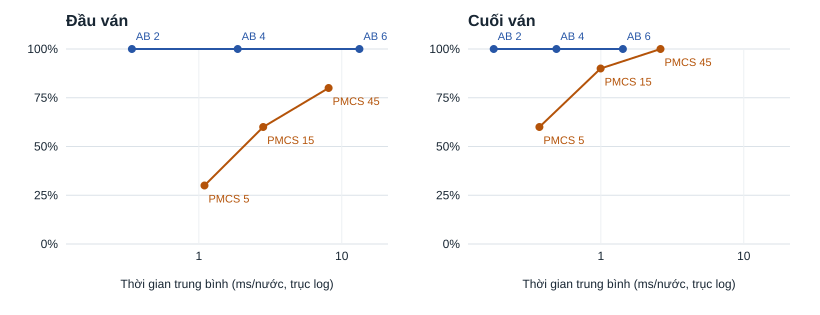

In [8]:
from html import escape
from math import log10


def tradeoff_chart(results):
    colors = {"AB": "#2756a6", "PMCS": "#b45309"}
    min_log = min(log10(ms) for ms, _ in results.values()) - 0.18
    max_log = max(log10(ms) for ms, _ in results.values()) + 0.2
    parts = [
        '<svg xmlns="http://www.w3.org/2000/svg" width="820" height="315" viewBox="0 0 820 315" role="img" aria-label="Thời gian và tỷ lệ đúng nước chiến thuật">',
        '<rect width="820" height="315" fill="#ffffff"/>',
        '<g fill="#182633" font-family="Arial, sans-serif" font-size="12">',
    ]
    for index, stage in enumerate(stages):
        x0 = 66 + index * 402
        y0, width, height = 244, 322, 195
        parts.append(f'<text x="{x0}" y="26" font-size="16" font-weight="bold">{stage} ván</text>')
        for rate in (0, .25, .5, .75, 1):
            y = y0 - rate * height
            parts.append(f'<path d="M{x0} {y}h{width}" stroke="#dbe2e8"/>')
            parts.append(f'<text x="{x0-8}" y="{y+4}" text-anchor="end">{rate:.0%}</text>')
        for tick in (0.1, 1, 10, 100, 1000):
            fraction = (log10(tick) - min_log) / (max_log - min_log)
            if 0 <= fraction <= 1:
                x = x0 + fraction * width
                parts.append(f'<path d="M{x} {y0-height}v{height}" stroke="#edf0f3"/>')
                parts.append(f'<text x="{x}" y="{y0+16}" text-anchor="middle">{tick:g}</text>')
        for name in families:
            points = []
            for parameter in families[name]:
                ms, accuracy = results[name, parameter, stage]
                x = x0 + (log10(ms) - min_log) / (max_log - min_log) * width
                y = y0 - accuracy * height
                points.append((x, y, parameter))
            joined = " ".join(f"{x},{y}" for x, y, _ in points)
            color = colors[name]
            parts.append(f'<polyline points="{joined}" fill="none" stroke="{color}" stroke-width="2"/>')
            for x, y, parameter in points:
                parts.append(f'<circle cx="{x}" cy="{y}" r="4" fill="{color}"/>')
                offset = -9 if name == "AB" else 17
                parts.append(f'<text x="{x+4}" y="{y+offset}" fill="{color}" font-size="11">{escape(name)} {parameter}</text>')
        parts.append(f'<text x="{x0+width/2}" y="288" text-anchor="middle">Thời gian trung bình (ms/nước, trục log)</text>')
    parts.append("</g></svg>")
    return "".join(parts)


chart_svg = tradeoff_chart(measurements)
try:
    from IPython.display import SVG, display
except ImportError:
    pass
else:
    display(SVG(chart_svg))

In [9]:
from statistics import mean


# Cấu hình được chọn sau khi đo thử trên các trạng thái ngẫu nhiên chưa kết thúc.
depth, samples = 4, 15
pilot_rng = Random(902)
pilot = []
for plies in (4, 8, 12, 16, 20, 24):
    board, player = empty_board(), 1
    for _ in range(plies):
        available = actions(board)
        if not available:
            break
        board = result(board, player, pilot_rng.choice(available))
        player = -player
    if not terminal(board):
        pilot.append((board, player))

pilot_ab = mean(MinimaxAgent(ordered=True, cutoff=depth).search(b, p).ms for b, p in pilot)
pilot_pmcs = mean(PMCSAgent(samples=samples, seed=11).search(b, p).ms for b, p in pilot)
print(f"{len(pilot)} bàn thử · AB {depth}: {pilot_ab:.3f} ms/nước · PMCS {samples}: {pilot_pmcs:.3f} ms/nước.")

rng = Random(902)
duel = {1: 0, 0: 0, -1: 0}
ab_times, pmcs_times = [], []
for opening in range(6):
    board, player = from_columns((6, 7), [rng.randrange(7) for _ in range(4)])
    for color in (1, -1):
        ab_agent = MinimaxAgent(ordered=True, cutoff=depth)
        pmcs_agent = PMCSAgent(samples=samples, seed=100 + opening)

        def ab_move(board, player):
            decision = ab_agent.search(board, player)
            ab_times.append(decision.ms)
            return decision.move

        def pmcs_move(board, player):
            decision = pmcs_agent.search(board, player)
            pmcs_times.append(decision.ms)
            return decision.move

        red, yellow = (ab_move, pmcs_move) if color == 1 else (pmcs_move, ab_move)
        value, _ = play(red, yellow, board, first=player)
        duel[color * value] += 1
print(f"12 ván từ 6 khai cuộc, đổi màu sau mỗi ván cùng khai cuộc: {counts_text(duel)} theo góc nhìn AB.")
print(f"Trong đối đầu · AB: {mean(ab_times):.3f} ms/nước · PMCS: {mean(pmcs_times):.3f} ms/nước.")

6 bàn thử · AB 4: 1.927 ms/nước · PMCS 15: 2.436 ms/nước.
12 ván từ 6 khai cuộc, đổi màu sau mỗi ván cùng khai cuộc: 9 thắng, 1 hòa, 2 thua theo góc nhìn AB.
Trong đối đầu · AB: 3.983 ms/nước · PMCS: 3.044 ms/nước.


Biểu đồ cho thấy độ chính xác chiến thuật và thời gian trên cùng bộ bàn. Cả ba độ sâu Alpha-Beta đều đạt 100% vì bộ kiểm tra chỉ yêu cầu nhìn một nước thắng hoặc hai lượt để thấy phản công. Tăng độ sâu trên bộ này làm tăng thời gian mà không đổi độ chính xác. Với PMCS, tăng số playout cải thiện độ chính xác ở cả hai giai đoạn. Cuối ván, số ô trống giảm nên các playout thường ngắn hơn.

Chọn Alpha-Beta cutoff 4 và PMCS N = 15 sau khi đo thử chi phí chọn nước. Trong đối đầu, Alpha-Beta thắng 9 ván, hòa 1 và thua 2. So sánh dùng 6 khai cuộc với hai cách phân màu. Chi phí mỗi nước thực tế thay đổi theo số cột mở, số ô trống và tỷ lệ cắt tỉa. Kết quả đối đầu đo trực tiếp khả năng chơi ở các khai cuộc này, còn tỷ lệ đúng trên đồ thị đo nhận diện thắng và chặn trong một lượt.